In [23]:
# !pip install pyDOE
# !pip install tensorflow
# !pip install pydot
# !pip install graphviz

In [24]:
import tensorflow as tf
import numpy as np
from pyDOE import lhs
import matplotlib.pyplot as plt
import pydot
import graphviz
import logging
import os

In [25]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
logging.getLogger('tensorflow').setLevel(logging.ERROR)

In [26]:
# print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
tf.config.list_physical_devices('GPU')
from tensorflow.python.client import device_lib
# print(device_lib.list_local_devices())

In [27]:
# Initial condition
x0, y0 = 0.9, 0.9

# Boundaries of the computational domain
t0, tfinal = 0.0, 7.0

In [28]:
a = 2/3
b = 4/3
c = 1
d = 1

In [29]:
decimal_p = 4

In [30]:
v0 = (c * x0) - (d * np.log(x0)) + (b * y0) - (a * np.log(y0))
print(v0)

2.275600859429711


In [31]:
with open('parameters/a=2,3_b=4,3_c=1_d=1_t0=0_tfinal=7_h=0.001.npy', 'rb') as f:

    points = np.load(f)

tpoints = points[0]
tpoints = np.round(tpoints, decimal_p)
xpoints = points[1]
ypoints = points[2]

In [32]:
# Define the normalization layer
class Normalize(tf.keras.layers.Layer):
  def __init__(self, xmin, xmax, name=None, **kwargs):
    super(Normalize, self).__init__(name=name)
    self.xmin = xmin
    self.xmax = xmax
    super(Normalize, self).__init__(**kwargs)

  def call(self, inputs):
    return 2.0*(inputs-self.xmin)/(self.xmax-self.xmin)-1.0

  def get_config(self):
    config = super(Normalize, self).get_config()
    config.update({'xmin': self.xmin, 'xmax': self.xmax})
    return config

In [33]:
# Define the network
def build_model(nr_units=40, nr_layers=4, summary=False):

  inp = b = tf.keras.layers.Input(shape=(1,))
  b = Normalize(t0, tfinal)(b)

  for i in range(nr_layers):
    b = tf.keras.layers.Dense(nr_units, activation='tanh')(b)
  outx = tf.keras.layers.Dense(1, activation='linear')(b)
  outy = tf.keras.layers.Dense(1, activation='linear')(b)

  model = tf.keras.models.Model(inp, [outx, outy])
  
  if summary:
    model.summary()

  return model

In [34]:
inputs = tf.keras.layers.Input(shape=(3,))
outputs = tf.keras.layers.Dense(2)(inputs)
model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer="Adam", loss="mse", metrics=["mae"])
model.metrics_names

model.summary()
# tf.keras.utils.plot_model(model)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 2)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

In [35]:
model = build_model(summary = True)

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalize_5         │ (None, 1)         │          0 │ input_layer_4[0]… │
│ (Normalize)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 40)        │         80 │ normalize_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 40)        │      1,640 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 40)        │      1,640 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 40)        │      1,640 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_18 (Dense)    │ (None, 1)         │         41 │ dense_17[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_19 (Dense)    │ (None, 1)         │         41 │ dense_17[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,082 (19.85 KB)

 Trainable params: 5,082 (19.85 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# tf.keras.utils.plot_model(model)

In [37]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N_pde=100):
    

    # Sample points where to evaluate the PDE
    ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N_pde)

    return ode_points

In [38]:
# Define the collocation points
de_points = defineCollocationPoints([t0, tfinal], 100)

Text(0.5, 1.0, 'Collocation points')

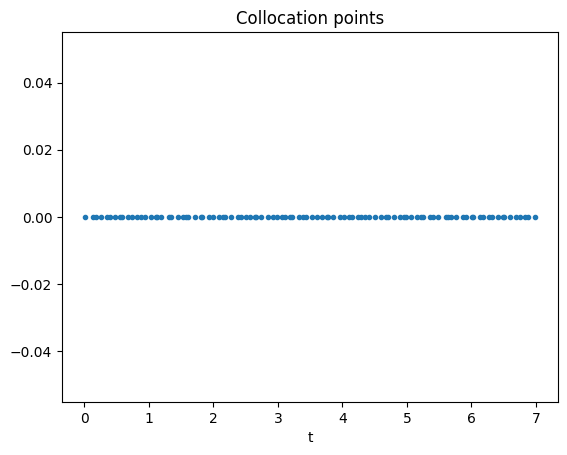

In [39]:
plt.plot(de_points[:,0], 0*de_points[:,0],'.')
plt.xlabel('t')
plt.title('Collocation points')
# plt.savefig('CollocationPoints1D.png')

In [40]:
# The main training function
@tf.function
def train_network(odes, inits, model, gamma):

    # DE collocation points
    t_de = odes[:,:1]

    # Initial value points
    t_init, x_init, y_init = inits[:1], inits[1:2], inits[2:]

    # Outer gradient for tuning network parameters
    with tf.GradientTape() as tape:

      # Inner gradient for derivatives of u wrt x and t
      with tf.GradientTape(persistent=True) as tape2:
        tape2.watch(t_de)
        [x, y] = model(t_de, training=True)

      # Derivative of the neural network solution
      xt = tape2.gradient(x, t_de)
      yt = tape2.gradient(y, t_de)
      
      # Define the differential equation loss  
      eqn1 = xt - (a*x - b*x*y)
      eqn2 = yt - (c*x*y - d*y)
      DEloss = tf.reduce_mean(tf.square(eqn1) + tf.square(eqn2))
                         
      # Define the initial value loss
      [x_init_pred, y_init_pred] = model(t_init, training=True)
      IVloss = tf.reduce_mean(tf.square(x_init_pred - x_init) + tf.square(y_init_pred - y_init))
    
      # Composite loss function
      loss = DEloss + gamma*IVloss

    grads = tape.gradient(loss, model.trainable_variables)
    return DEloss, IVloss, grads

In [41]:
def PINNtrain(de_points, x0, y0, epochs, gamma_val):

  # Total number of collocation points
  N_de = len(de_points)

  # Batch size
  bs_de = N_de//10

  # Weight factor gamma
  gamma = gamma_val

  # Learning rate
  lr_model = 1e-3

  # Initial value
  t_init = np.array([t0]).astype(np.float32)
  x_init = np.array([x0]).astype(np.float32)
  y_init = np.array([y0]).astype(np.float32)

  epoch_loss = np.zeros(epochs)
  nr_batches = 0

  # Generate the tf.Dataset for the initial collocation points
  inits = np.column_stack([t_init, x_init, y_init])
  ds_init = tf.data.Dataset.from_tensor_slices(inits)
  ds_init = ds_init.cache()


  # Generate the tf.Dataset for the differential equations points
  ds_ode = tf.data.Dataset.from_tensor_slices(de_points.astype(np.float32))
  ds_ode = ds_ode.cache().shuffle(N_de).batch(bs_de)

  # Generate entire dataset
  ds = tf.data.Dataset.zip((ds_ode, ds_init))

  ds_list = ds.as_numpy_iterator()

  ds = ds.prefetch(tf.data.experimental.AUTOTUNE)

  # Generate the model
  opt = tf.keras.optimizers.Adam(lr_model)
  model = build_model() 

  # Main training loop
  for i in range(epochs):

    # Training for that epoch
    for (des, inits) in ds:

      # Train the network
      DEloss, IVloss, grads = train_network(des, inits, model, gamma)

      # Gradient step
      opt.apply_gradients(zip(grads, model.trainable_variables))
      
      epoch_loss[i] += DEloss + gamma*IVloss
      nr_batches = nr_batches + 1

    # Get total epoch loss
    epoch_loss[i] = epoch_loss[i]/nr_batches
    nr_batches = 0

    if (np.mod(i, 500)==0):
      print("DE loss, IV loss in {}th epoch: {: 6.4f}, {: 6.4f}.".format(i, DEloss, IVloss))

  return epoch_loss, model

In [42]:
def train_plot(epochs, gamma) :
    
    loss, model = PINNtrain(de_points, x0, y0, epochs, gamma)
    
    # Grid where to evaluate the model
    m = 1000
    t = np.linspace(t0, tfinal, m)
    
    plt.figure(1)
    plt.plot(loss)
    plt.xlabel("epoch")
    plt.ylabel("loss")

    # Model prediction
    [x, y] = model(t)
    
    # Plot the solution
    
    # print(len(x))
    
    plt.figure(2)
    plt.plot(x, y, label = "e = " + str(epochs) + ", gamma = " + str(gamma))
    plt.legend(loc='best')
    plt.plot(xpoints, ypoints, color = 'black')
    plt.xlabel("x")
    plt.ylabel("y")
    
    v = (c * x) - (d * np.log(x)) + (b * y) - (a * np.log(y))
    v = v - v0
    
    plt.figure(3)
    plt.plot([i for i in range(v.shape[0])], v)
    plt.xlabel("time")
    plt.ylabel("error in v")
    

DE loss, IV loss in 0th epoch:  0.0254,  1.4719.
DE loss, IV loss in 500th epoch:  0.0443,  0.0017.
DE loss, IV loss in 1000th epoch:  0.0289,  0.0003.
DE loss, IV loss in 1500th epoch:  0.0169,  0.0004.
DE loss, IV loss in 2000th epoch:  0.0142,  0.0004.
DE loss, IV loss in 2500th epoch:  0.0150,  0.0003.
DE loss, IV loss in 3000th epoch:  0.0174,  0.0007.


2026-10-25 18:20:12.858245: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


DE loss, IV loss in 3500th epoch:  0.0034,  0.0001.
DE loss, IV loss in 4000th epoch:  0.0035,  0.0001.
DE loss, IV loss in 4500th epoch:  0.0042,  0.0000.


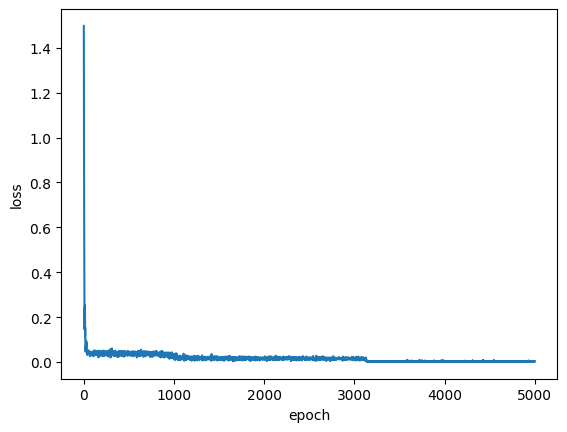

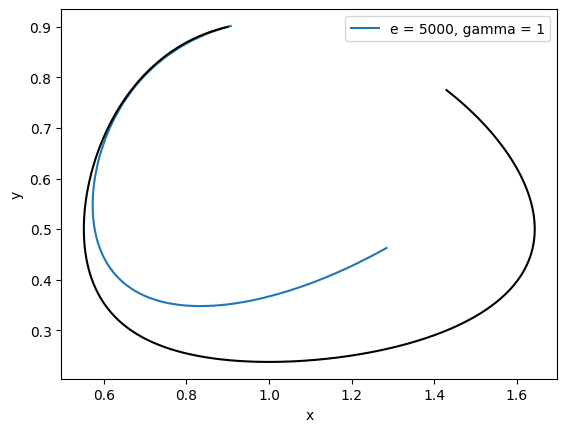

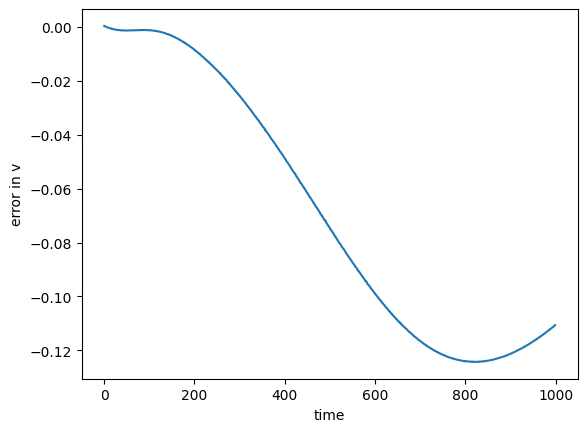

In [43]:
epochs = 10000

train_plot(epochs, 1)
# train_plot(epochs, 0.8)